# Financial Performance

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which markets generate the highest sales and profits?

This question was already answered in the [Geographic Performance Analysis](./04-geographic-performance-analysis.ipynb). There we can see that:

1. Europe generates the most profits ($1,131,938) and revenue ($10,405,371)
2. LATAM follows with $1,069,051 in profits, $9,824,330 in revenue
3. Pacific Asia - $826,167 in profits, $7,942,352 in revenue
4. USCA - $539,223 in profits,$4,836,414 in revenue
5. Africa is last with $240,041 in profits and $2,205,963 in revenue

## Which product categories are the most profitable?

In [3]:
profit_per_product_category = df.groupby('category_name')['order_item_profit'].sum().sort_values(ascending=False)

total_profit = profit_per_product_category.sum()
most_profitable = profit_per_product_category.head(8)

for category, profit in most_profitable.items():
    print(f'{category}: ${profit:,.0f} ({(profit / total_profit):.2%} of global profit)')

Fishing: $731,576 (19.22% of global profit)
Cleats: $474,630 (12.47% of global profit)
Camping & Hiking: $409,896 (10.77% of global profit)
Cardio Equipment: $362,985 (9.54% of global profit)
Women's Apparel: $334,336 (8.78% of global profit)
Water Sports: $308,981 (8.12% of global profit)
Indoor/Outdoor Games: $302,404 (7.94% of global profit)
Men's Footwear: $296,711 (7.80% of global profit)


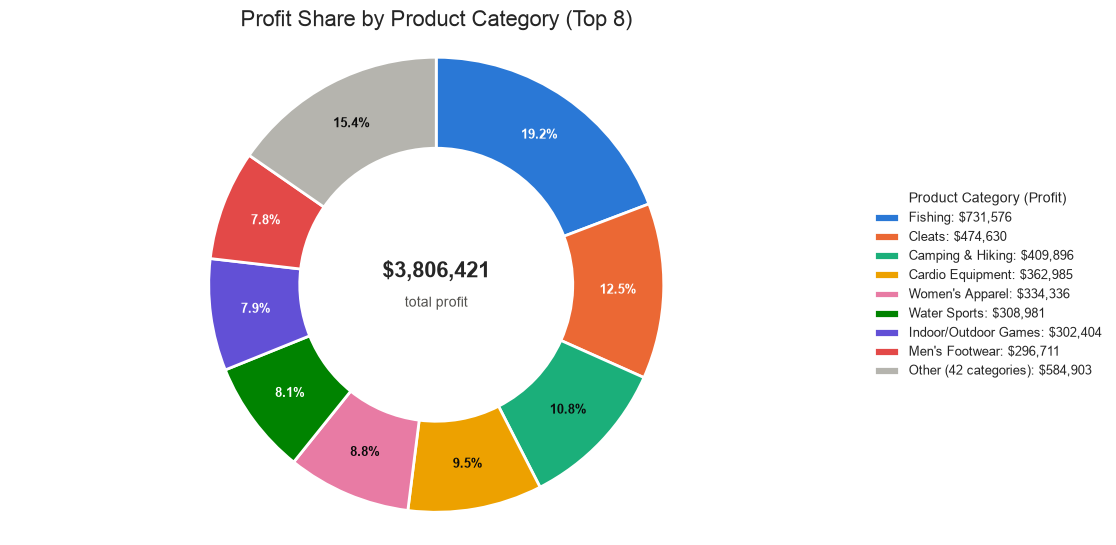

In [4]:
top_n = 8

top_categories = profit_per_product_category.head(top_n)
other_profit = profit_per_product_category.iloc[top_n:].sum()
other_count = len(profit_per_product_category) - top_n

donut_data = pd.concat([top_categories, pd.Series({f'Other ({other_count} categories)': other_profit})])

colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948', '#b5b4ae']

legend_labels = [
    f'{category}: ${profit:,.0f}'
    for category, profit in donut_data.items()
]

fig, ax = plt.subplots(figsize=(11, 6.5))

wedges, _, pct_labels = ax.pie(
    donut_data,
    startangle=90,
    counterclock=False,
    colors=colors,
    autopct='%1.1f%%',
    pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
)

light_colors = {'#1baf7a', '#eda100', '#e87ba4', '#b5b4ae'}

for label, color in zip(pct_labels, colors):
    label.set_fontsize(9)
    label.set_fontweight('bold')
    label.set_color('#0b0b0b' if color in light_colors else 'white')

ax.text(0, 0.06, f'${total_profit:,.0f}', ha='center', va='center', fontsize=16, fontweight='bold')
ax.text(0, -0.08, 'total profit', ha='center', va='center', fontsize=10, color='#52514e')

ax.legend(
    wedges,
    legend_labels,
    title='Product Category (Profit)',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title('Profit Share by Product Category (Top 8)', fontsize=16)
ax.axis('equal')

plt.savefig('../visualizations/profit-share-by-product-category.png', bbox_inches='tight')
plt.show()

## How do discounts affect profit margins?

## Which customer segments contribute most to revenue and profit?